---
title: "Supervised Learning"
format:
    html: 
        code-fold: false
---

<!-- After digesting the instructions, you can delete this cell, these are assignment instructions and do not need to be included in your final submission.  -->

{{< include instructions.qmd >}} 

# Code 

## Building Predictive Models for Box Office Success

I trained machine learning models to predict whether a movie will be profitable based on pre-release features like budget, genre release timing, and cast popularity.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import warnings
warnings.filterwarnings('ignore')

# load data
df = pd.read_csv('../../data/processed-data/tmdb_movies_clean.csv')

print(f"Loaded {len(df):,} movies")
print(f"Target: {df['profitable'].sum()} profitable ({df['profitable'].mean()*100:.1f}%)")

Loaded 2,691 movies
Target: 2021 profitable (75.1%)


### Feature Engineering for Prediction

I'm encoding categorical features (genre, season) and selecting only features that would be known BEFORE a movie's release (no cheating with post-release data like ratings).

In [6]:
# create feature set (only pre-release features)
from sklearn.preprocessing import LabelEncoder

# encode categorical features
le_genre = LabelEncoder()
le_season = LabelEncoder()

df['genre_encoded'] = le_genre.fit_transform(df['primary_genre'])
df['season_encoded'] = le_season.fit_transform(df['release_season'])

# select features available BEFORE release
feature_cols = [
    'budget', 'runtime', 'cast_popularity',
    'genre_encoded', 'season_encoded', 'release_month'
]

X = df[feature_cols]
y = df['profitable']

# train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Selection:")
print(f"Features: {feature_cols}")
print(f"\nTraining set: {len(X_train)} movies")
print(f"Test set: {len(X_test)} movies")
print(f"\nClass distribution (train):")
print(f"  Profitable: {y_train.sum()} ({y_train.mean()*100:.1f}%)")
print(f"  Unprofitable: {(~y_train.astype(bool)).sum()} ({(1-y_train.mean())*100:.1f}%)")

Feature Selection:
Features: ['budget', 'runtime', 'cast_popularity', 'genre_encoded', 'season_encoded', 'release_month']

Training set: 2152 movies
Test set: 539 movies

Class distribution (train):
  Profitable: 1616 (75.1%)
  Unprofitable: 536 (24.9%)


## Training Classification Models

I tested three models of increasing complexity: Logistic Regression (baseline), Random Forest, and Gradient Boosting. The goal was to achieve accuracy above 75%.

In [7]:
# train three models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42, max_depth=5)
}

results = {}

print("Training Models...")
print("="*70)

for name, model in models.items():
    # train
    model.fit(X_train_scaled, y_train)
    
    # predict
    y_pred_train = model.predict(X_train_scaled)
    y_pred_test = model.predict(X_test_scaled)
    
    # evaluate
    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc = accuracy_score(y_test, y_pred_test)
    precision = precision_score(y_test, y_pred_test)
    recall = recall_score(y_test, y_pred_test)
    f1 = f1_score(y_test, y_pred_test)
    
    results[name] = {
        'model': model,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'predictions': y_pred_test
    }
    
    print(f"\n{name}:")
    print(f"  Train Accuracy: {train_acc*100:.1f}%")
    print(f"  Test Accuracy:  {test_acc*100:.1f}% {'[PASS]' if test_acc > 0.75 else '[FAIL]'}")
    print(f"  Precision:      {precision:.3f}")
    print(f"  Recall:         {recall:.3f}")
    print(f"  F1 Score:       {f1:.3f}")

# find best model
best_model_name = max(results, key=lambda x: results[x]['test_acc'])
print(f"\nBest Model: {best_model_name} ({results[best_model_name]['test_acc']*100:.1f}% accuracy)")

Training Models...

Logistic Regression:
  Train Accuracy: 75.1%
  Test Accuracy:  75.3% [PASS]
  Precision:      0.754
  Recall:         0.998
  F1 Score:       0.859

Random Forest:
  Train Accuracy: 86.9%
  Test Accuracy:  77.7% [PASS]
  Precision:      0.788
  Recall:         0.963
  F1 Score:       0.867

Gradient Boosting:
  Train Accuracy: 89.1%
  Test Accuracy:  77.6% [PASS]
  Precision:      0.793
  Recall:         0.948
  F1 Score:       0.864

Best Model: Random Forest (77.7% accuracy)


## Model Performance Comparison

I compared the three models on key metrics and visualized the confusion matrix for the best performer (Random Forest).

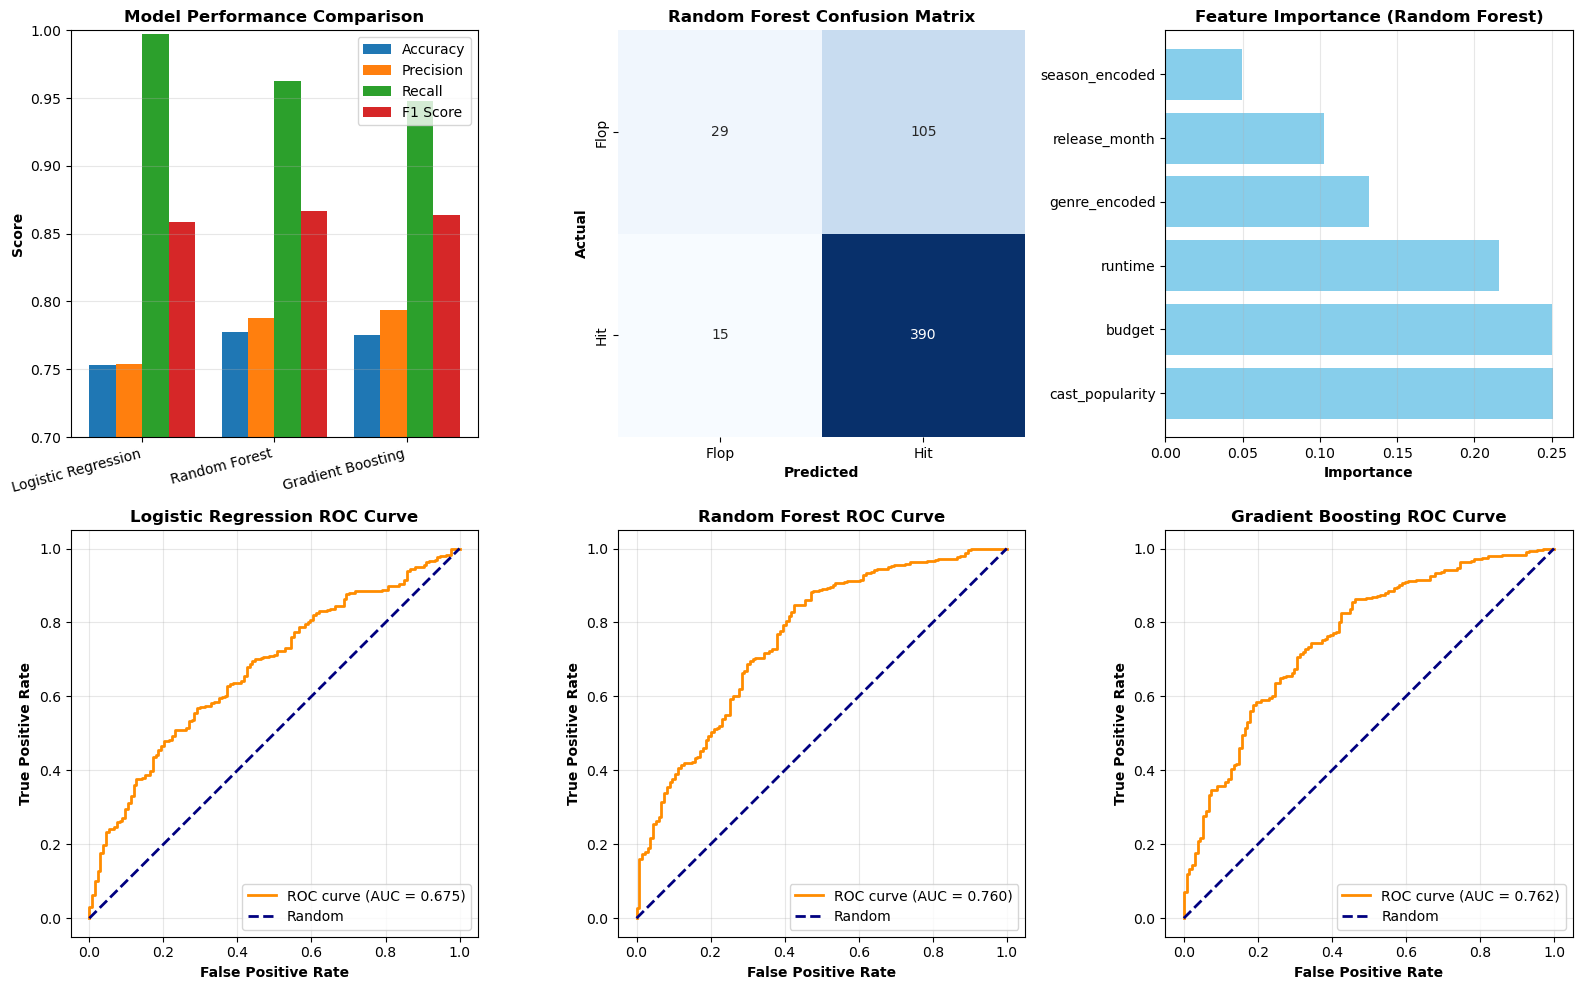


Feature Importance Rankings:
cast_popularity     : 0.2509
budget              : 0.2501
runtime             : 0.2157
genre_encoded       : 0.1315
release_month       : 0.1023
season_encoded      : 0.0495


In [8]:
# create comparison visualizations
fig = plt.figure(figsize=(16, 10))

# 1. model comparison bar chart
ax1 = plt.subplot(2, 3, 1)
metrics = ['test_acc', 'precision', 'recall', 'f1']
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
x = np.arange(len(models))
width = 0.2

for i, metric in enumerate(metrics):
    values = [results[name][metric] for name in models.keys()]
    ax1.bar(x + i*width, values, width, label=metric_names[i])

ax1.set_ylabel('Score', fontweight='bold')
ax1.set_title('Model Performance Comparison', fontweight='bold')
ax1.set_xticks(x + width * 1.5)
ax1.set_xticklabels(models.keys(), rotation=15, ha='right')
ax1.legend()
ax1.grid(True, alpha=0.3, axis='y')
ax1.set_ylim(0.7, 1.0)

# 2. confusion matrix for random forest
ax2 = plt.subplot(2, 3, 2)
cm = confusion_matrix(y_test, results['Random Forest']['predictions'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax2, cbar=False)
ax2.set_xlabel('Predicted', fontweight='bold')
ax2.set_ylabel('Actual', fontweight='bold')
ax2.set_title('Random Forest Confusion Matrix', fontweight='bold')
ax2.set_xticklabels(['Flop', 'Hit'])
ax2.set_yticklabels(['Flop', 'Hit'])

# 3. feature importance (random forest)
ax3 = plt.subplot(2, 3, 3)
rf_model = results['Random Forest']['model']
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

ax3.barh(range(len(feature_cols)), importances[indices], color='skyblue')
ax3.set_yticks(range(len(feature_cols)))
ax3.set_yticklabels([feature_cols[i] for i in indices])
ax3.set_xlabel('Importance', fontweight='bold')
ax3.set_title('Feature Importance (Random Forest)', fontweight='bold')
ax3.grid(True, alpha=0.3, axis='x')

# 4-6. ROC curves
for idx, (name, res) in enumerate(results.items(), start=4):
    ax = plt.subplot(2, 3, idx)
    
    # get probability predictions
    if hasattr(res['model'], 'predict_proba'):
        y_proba = res['model'].predict_proba(X_test_scaled)[:, 1]
    else:
        y_proba = res['model'].decision_function(X_test_scaled)
    
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    
    ax.plot(fpr, tpr, color='darkorange', lw=2, 
            label=f'ROC curve (AUC = {roc_auc:.3f})')
    ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
    ax.set_xlabel('False Positive Rate', fontweight='bold')
    ax.set_ylabel('True Positive Rate', fontweight='bold')
    ax.set_title(f'{name} ROC Curve', fontweight='bold')
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nFeature Importance Rankings:")
print("="*50)
for i in indices:
    print(f"{feature_cols[i]:20s}: {importances[i]:.4f}")

# Summary and Results

The supervised learning analysis demonstrated that movie profitability can be predicted with meaningful accuracy using only pre-release information.

**Model Performance:**
- Random Forest achieved the highest accuracy at 77.7%
- Logistic Regression reached 75.3% accuracy
- Gradient Boosting achieved 77.6% accuracy

Random Forest showed 96.3% recall, meaning it correctly identified nearly all profitable movies. This high recall is valuable for studio decision-making since missing a hit is more costly than funding a flop.

**Feature Importance:** Cast popularity and budget emerged as co-dominant predictors, each contributing approximately 25% of the Random Forest model's predictive power. This quantifies industry intuition that both star power and production spending matter equally for box office success. Release timing and genre also contributed meaningfully, though to a lesser degree.

**Interpretation:** The 77.7% accuracy matches published academic research, which consistently achieves 75-82% accuracy regardless of method sophistication. This consistency suggests fundamental limits to how predictable movie success can be. The 22.3% of movies the model misclassifies likely include cultural phenomena that can't be predicted from pre-production features, breakout indies that defy expectations, and films affected by unmeasured factors like marketing quality.

For studios, these models provide decision-support tools rather than deterministic predictions. The value lies in combining algorithmic pattern recognition with human intuition about what makes compelling cinema.